# Attack day model training

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
from pathlib import Path


PROJECT_ROOT = Path("/content/drive/MyDrive/master-thesis").resolve()

SRC_PATH = PROJECT_ROOT / "src"
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
RUNS_DIR = PROJECT_ROOT / "runs"

SEED = 42

os.chdir(PROJECT_ROOT)

sys.path.append(str(PROJECT_ROOT))
sys.path.append(str(SRC_PATH))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import logging
import json
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit, cross_val_score

from notebooks.targeted_experiment_utils import (
    ATSSetup,
    TARGET_SIGNALS,
    candidate_attack_days
)

from scr.attack_day_model.create_data import create_attack_event_log
from scr.attack_day_model.preprocessing import prepare_attack_day_dataset, feature_correlation_analysis, chronological_train_test_split, TECHNICAL_FEATURE_COLUMNS, NON_FEATURE_COLUMNS
from scr.attack_day_model.model import build_model, evaluate, find_best_threshold, load_X, load_y, predict, save_model, load_model, feature_importance, ImbalanceStrategy, tune_model, fit_params_for

print("PROJECT_ROOT:", PROJECT_ROOT)
print("SRC_PATH:", SRC_PATH)
print("Current dir:", Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_ROOT: /content/drive/MyDrive/master-thesis
SRC_PATH: /content/drive/MyDrive/master-thesis/src
Current dir: /content/drive/MyDrive/master-thesis


In [4]:
MODEL_FOLDERS = {
    "LSTM": RUNS_DIR / f"seed_{SEED}/models/LSTM_13_years",
    "LSTM3y": RUNS_DIR / f"seed_{SEED}/models/LSTM_3_years",
    "LSTM_cumulative": RUNS_DIR / f"seed_{SEED}/models/LSTM_cumulative",
    "LSTM_rolling": RUNS_DIR / f"seed_{SEED}/models/LSTM_rolling",
    "transformer": NOTEBOOK_DIR / "models/transformer",
}

ATTACK_MODEL_FOLDER = NOTEBOOK_DIR / "models/attack_day"

DATA_FOLDER = PROJECT_ROOT / "data/validation_time"

DATA_START       = "2013-01-01"
VALIDATION_START = "2021-01-01"
VALIDATION_END   = "2023-10-23"
ATTACK_START     = "2014-01-01"
ATTACK_END       = "2026-06-01"
QUARTERLY_MONTHS          = 3
EVALUATION_WINDOW_DAYS    = 20

TRAIN_MODE_BY_SETUP = {
    "LSTM_rolling_ALL_MA":      "rolling",
    "LSTM_rolling_All_BB":      "rolling",
    "LSTM_rolling_All_ROC":     "rolling",
    "LSTM_cumulative_All_BB":   "cumulative",
    "LSTM3y_All_BB":            "cumulative",
    "LSTM13y_All_BB":           "cumulative",
}

EXPERIMENT_NAME  = "attack_dataset_(GOOGL)"
DATASET_DIR      = PROJECT_ROOT / f"data/{EXPERIMENT_NAME}"
DATASET_PATH     = DATASET_DIR / f"{EXPERIMENT_NAME}.csv"

model_path = ATTACK_MODEL_FOLDER / "attack_day_googl.pkl"
meta_path  = ATTACK_MODEL_FOLDER / "metadata_googl.json"

FEATURE_DATASET_PATH    = DATASET_DIR / f"{EXPERIMENT_NAME}_features.csv"
MODEL_COMPARISON_PATH   = DATASET_DIR / f"{EXPERIMENT_NAME}_model_comparison.csv"
X_train_PATH            = DATASET_DIR / f"{EXPERIMENT_NAME}_X_train.csv"
y_train_PATH            = DATASET_DIR / f"{EXPERIMENT_NAME}_y_train.csv"
X_test_PATH             = DATASET_DIR / f"{EXPERIMENT_NAME}_X_test.csv"
y_test_PATH             = DATASET_DIR / f"{EXPERIMENT_NAME}_y_test.csv"

ALL_TICKERS = [
    "GOOGL", "AMZN", "AAPL", "PEP", "JNJ", "PFE", "MRK", "ABBV", "PG", "KO",
    "WMT", "JPM", "BAC", "GS", "V", "XOM", "CVX", "COP", "BP", "BA",
    "MMM", "HON", "GE", "T", "VZ", "TMUS", "HSY", "DUK", "SO", "EXC", "AEP",
    "AMT", "PLD", "SPG", "BHP", "RIO", "VALE", "FCX",
]

SEQUENCE_LENGTH = 50
MAX_ABS_DELTA   = 2
GRID_STEPS      = 40

np.random.seed(SEED)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
    force=True,
)
logger = logging.getLogger(__name__)

SETUPS = [
    ATSSetup("LSTM3y_All_ROC_AAPL", tuple(ALL_TICKERS), "ROC", model_name="LSTM3y",   model_variant="single", attacked_ticker="AAPL"),
    ATSSetup("LSTM13y_All_ROC_AAPL", tuple(ALL_TICKERS), "ROC", model_name="LSTM",   model_variant="single", attacked_ticker="AAPL"),
    ATSSetup("LSTM3y_All_MA_AAPL",   tuple(ALL_TICKERS), "MA",  model_name="LSTM3y", model_variant="single", attacked_ticker="AAPL"),
    ATSSetup("LSTM13y_All_MA_AAPL",  tuple(ALL_TICKERS), "MA",  model_name="LSTM",   model_variant="single", attacked_ticker="AAPL"),
    ATSSetup("LSTM3y_All_ROC_GOOGL", tuple(ALL_TICKERS), "ROC", model_name="LSTM3y",   model_variant="single", attacked_ticker="GOOGL"),
    ATSSetup("LSTM13y_All_ROC_GOOGL", tuple(ALL_TICKERS), "ROC", model_name="LSTM",   model_variant="single", attacked_ticker="GOOGL"),
    ATSSetup("LSTM3y_All_MA__GOOGL",   tuple(ALL_TICKERS), "MA",  model_name="LSTM3y", model_variant="single", attacked_ticker="GOOGL"),
    ATSSetup("LSTM13y_All_MA_GOOGL",  tuple(ALL_TICKERS), "MA",  model_name="LSTM",   model_variant="single", attacked_ticker="GOOGL"),
    #ATSSetup("LSTM3y_All_ROC_AMZN", tuple(ALL_TICKERS), "ROC", model_name="LSTM3y",   model_variant="single", attacked_ticker="AMZN"),
    #ATSSetup("LSTM13y_All_ROC_AMZN", tuple(ALL_TICKERS), "ROC", model_name="LSTM",   model_variant="single", attacked_ticker="AMZN"),
    #ATSSetup("LSTM3y_All_MA__AMZN",   tuple(ALL_TICKERS), "MA",  model_name="LSTM3y", model_variant="single", attacked_ticker="AMZN"),
    #ATSSetup("LSTM13y_All_MA_AMZN",  tuple(ALL_TICKERS), "MA",  model_name="LSTM",   model_variant="single", attacked_ticker="AMZN"),
]


def count_attack_outcomes(df: pd.DataFrame) -> dict:
    """Count positive / negative / hard-negative outcomes in the event log."""
    col = df["delta_cumulative_return_in_period"]
    return {
        "positive":      int((col < 0).sum()),
        "negative":      int(col.isna().sum() + (col == 0).sum()),
        "hard_negative": int((col > 0).sum()),
    }

def load_attack_model(model_path, meta_path, logger):
    model = load_model(model_path, logger)

    with open(meta_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    return {
        "model": model,
        "threshold": metadata["threshold"],
        "feature_columns": metadata["feature_columns"],
        "metadata": metadata,
    }

## 1 - Create dataset

In [ ]:
DATASET_DIR.mkdir(parents=True, exist_ok=True)
print(f"Creating attack event log → {DATASET_PATH}")

for setup in SETUPS:
    train_mode = TRAIN_MODE_BY_SETUP.get(setup.name, "cumulative")
    attack_days = candidate_attack_days(
        setup=setup,
        model_folders=MODEL_FOLDERS,
        project_root=PROJECT_ROOT,
        data_folder=DATA_FOLDER,
        sequence_length=SEQUENCE_LENGTH,
        min_day=0,
        simulation_start=ATTACK_START,
        simulation_end=VALIDATION_START,
        data_start=DATA_START,
        months=QUARTERLY_MONTHS,
        train_mode=train_mode,
        use_yahoo_api=True
    )
    print(f"  {setup.name}: {attack_days.tolist()}")
    create_attack_event_log(
        setups=[setup],
        attack_days=attack_days,
        model_folders=MODEL_FOLDERS,
        project_root=PROJECT_ROOT,
        output_csv=DATASET_PATH,
        target_signals=TARGET_SIGNALS,
        timing_policy="manual",
        data_folder=DATA_FOLDER,
        sequence_length=SEQUENCE_LENGTH,
        max_abs_delta=MAX_ABS_DELTA,
        steps=GRID_STEPS,
        simulation_start=ATTACK_START,
        simulation_end=VALIDATION_START,
        data_start=DATA_START,
        months=QUARTERLY_MONTHS,
        eval_cr_period=EVALUATION_WINDOW_DAYS,
        train_mode=train_mode,
        resume=True,
        ignore_already_target=True,
        checkpoint_every=10,
        verbose=True,
        use_yahoo_api=True,
    )

In [4]:
event_log = pd.read_csv(DATASET_PATH)
print(f"\nEvent log saved → {DATASET_PATH}")
print(f"Rows: {len(event_log)}")
outcomes = count_attack_outcomes(event_log)
print(f"  - Positive: {outcomes['positive']}  \n  - Negative: {outcomes['negative']}  \n  - Hard negative: {outcomes['hard_negative']}")


Event log saved → /content/drive/MyDrive/master-thesis/data/attack_dataset_1/attack_dataset_1.csv
Rows: 15733
  - Positive: 1639  
  - Negative: 12548  
  - Hard negative: 1546


## 2 - Preprocess data

In [4]:
print("Preprocessing attack dataset for ML training...")

attack_dataset = prepare_attack_day_dataset(
    csv_path=DATASET_PATH,
    price_data_folder=DATA_FOLDER,
    simulation_start=ATTACK_START,
    simulation_end=ATTACK_END,
    data_start=DATA_START,
    sequence_length=SEQUENCE_LENGTH,
    ohlcv_window=20,
    target_col="target",
    include_categoricals=True,
    drop_invalid=True,
    drop_already_target=True,
    prefer_download=True,
    verbose=True,
)

raw_attack_log   = attack_dataset["raw"]
feature_df       = attack_dataset["features"]
feature_columns  = [col for col in attack_dataset["feature_columns"] if col != "attack_day"]

train_df, test_df = chronological_train_test_split(feature_df)

X_train = train_df[feature_columns].copy()
X_test  = test_df[feature_columns].copy()
y_train = train_df["target"].astype(int)
y_test  = test_df["target"].astype(int)

print(f"Raw rows        : {len(raw_attack_log)}")
print(f"Feature rows    : {len(feature_df)}")
print(f"Feature columns : {len(feature_columns)}")
print(f"X_train shape   : {X_train.shape}  |  y_train shape: {y_train.shape}")
print(f"X_test  shape   : {X_test.shape}   |  y_test  shape: {y_test.shape}")

# save to csv
feature_df.to_csv(FEATURE_DATASET_PATH, index=False)
X_train.to_csv(X_train_PATH, index=False, sep=";")
y_train.to_csv(y_train_PATH, index=False)
X_test.to_csv(X_test_PATH,  index=False, sep=";")
y_test.to_csv(y_test_PATH,  index=False)
print(f"\nPreprocessed files saved to: {DATASET_DIR}")

Preprocessing attack dataset for ML training...
Built 15643 feature rows. Skipped 0.
Raw rows        : 15643
Feature rows    : 15643
Feature columns : 133
X_train shape   : (12514, 133)  |  y_train shape: (12514,)
X_test  shape   : (3129, 133)   |  y_test  shape: (3129,)

Preprocessed files saved to: /content/drive/MyDrive/master-thesis/data/attack_dataset_(GOOGL)


## 3 - Load data

In [5]:
if not FEATURE_DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Preprocessed dataset not found: {FEATURE_DATASET_PATH}\n"
        "Run section 2 first to generate it."
    )

feature_df = pd.read_csv(FEATURE_DATASET_PATH)

X_train = load_X(X_train_PATH, logger)
X_test  = load_X(X_test_PATH,  logger)
y_train = load_y(y_train_PATH, logger)
y_test  = load_y(y_test_PATH,  logger)

# remove leftover AMZN rows
#keep_tr = X_train.get("attacked_ticker_AMZN", 0) == 0
#keep_te = X_test.get("attacked_ticker_AMZN", 0) == 0
#X_train, y_train = X_train[keep_tr].reset_index(drop=True), y_train[keep_tr].reset_index(drop=True)
#X_test,  y_test  = X_test[keep_te].reset_index(drop=True),  y_test[keep_te].reset_index(drop=True)

# keep only GOOGL attacks (drops AAPL and the leftover AMZN rows)
keep_tr = X_train["attacked_ticker_GOOGL"] == 1
keep_te = X_test["attacked_ticker_GOOGL"] == 1
X_train, y_train = X_train[keep_tr].reset_index(drop=True), y_train[keep_tr].reset_index(drop=True)
X_test,  y_test  = X_test[keep_te].reset_index(drop=True),  y_test[keep_te].reset_index(drop=True)

cat_prefixes = ("setup_", "model_", "strategy_", "attacked_ticker_", "timing_policy_")
columns_to_drop = ["attack_day", "attack_date"] + [c for c in X_train.columns if c.startswith(cat_prefixes)]
X_train = X_train.drop(columns=columns_to_drop, errors="ignore")
X_test  = X_test.drop(columns=columns_to_drop, errors="ignore")

print(f"Loaded  X_train: {X_train.shape}  |  y_train: {y_train.shape}")
print(f"Loaded  X_test : {X_test.shape}   |  y_test : {y_test.shape}")

2026-11-05 14:55:59 [INFO] Loaded X from '/content/drive/MyDrive/master-thesis/data/attack_dataset_(GOOGL)/attack_dataset_(GOOGL)_X_train.csv' – shape (12514, 133)
2026-11-05 14:56:04 [INFO] Applied feature engineering – new shape (12514, 157)
2026-11-05 14:56:05 [INFO] Loaded X from '/content/drive/MyDrive/master-thesis/data/attack_dataset_(GOOGL)/attack_dataset_(GOOGL)_X_test.csv' – shape (3129, 133)
2026-11-05 14:56:06 [INFO] Applied feature engineering – new shape (3129, 157)
2026-11-05 14:56:06 [INFO] Loaded y from '/content/drive/MyDrive/master-thesis/data/attack_dataset_(GOOGL)/attack_dataset_(GOOGL)_y_train.csv' – 12514 samples
2026-11-05 14:56:06 [INFO]   Class 0 (non attack): 11146 (89.1%)
2026-11-05 14:56:06 [INFO]   Class 1 (attack): 1368 (10.9%)
2026-11-05 14:56:06 [INFO]   Imbalance ratio: 1:8 (non attack : attack)
2026-11-05 14:56:06 [WARNING] Moderate imbalance detected (1:8). Recommend ImbalanceStrategy.SMOTE or CLASS_WEIGHT.
2026-11-05 14:56:07 [INFO] Loaded y from '/

Loaded  X_train: (6256, 140)  |  y_train: (6256,)
Loaded  X_test : (1555, 140)   |  y_test : (1555,)


## 4 - Feature correlation

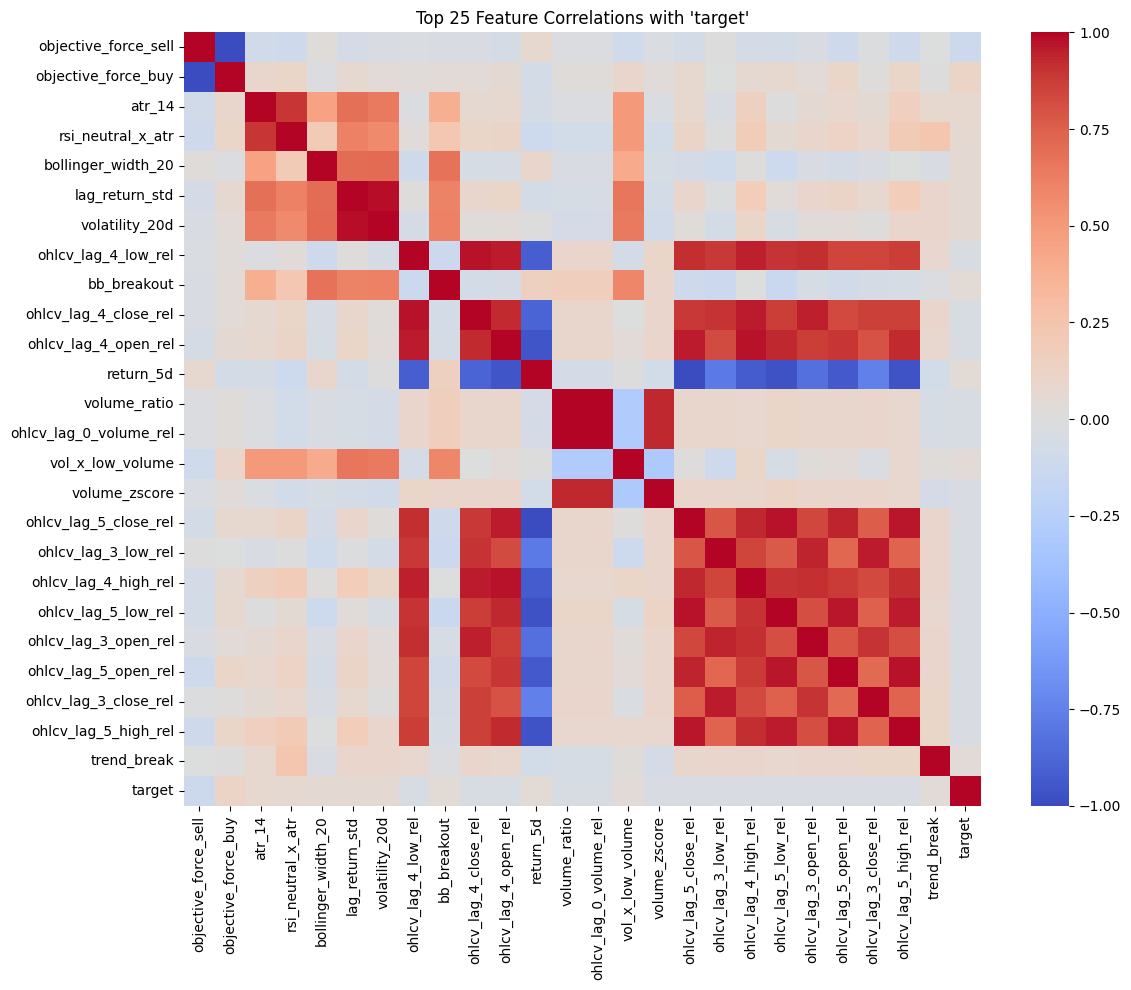


Top features correlated with target:

objective_force_sell     -0.124110
objective_force_buy       0.124110
atr_14                    0.077089
rsi_neutral_x_atr         0.067516
bollinger_width_20        0.058371
lag_return_std            0.057000
volatility_20d            0.056520
ohlcv_lag_4_low_rel      -0.044747
bb_breakout               0.044284
ohlcv_lag_4_close_rel    -0.042292
ohlcv_lag_4_open_rel     -0.041294
return_5d                 0.039861
volume_ratio             -0.039497
ohlcv_lag_0_volume_rel   -0.039497
vol_x_low_volume          0.038780
volume_zscore            -0.038676
ohlcv_lag_5_close_rel    -0.037402
ohlcv_lag_3_low_rel      -0.037360
ohlcv_lag_4_high_rel     -0.037257
ohlcv_lag_5_low_rel      -0.037248
ohlcv_lag_3_open_rel     -0.036651
ohlcv_lag_5_open_rel     -0.035864
ohlcv_lag_3_close_rel    -0.034699
ohlcv_lag_5_high_rel     -0.034207
trend_break               0.034093
Name: target, dtype: float64


,target
objective_force_sell,-0.124110
objective_force_buy,0.124110
atr_14,0.077089
rsi_neutral_x_atr,0.067516
bollinger_width_20,0.058371
...,...
ohlcv_lag_2_volume_rel,-0.000774
ohlcv_lag_16_close_rel,-0.000601
ohlcv_lag_14_close_rel,-0.000446
lag_return_autocorr,-0.000320


In [6]:
df = pd.concat([X_train, y_train], axis=1)

feature_correlation_analysis(
    df,
    target_col="target",
    top_k=25,
)

## 5 - Train model

In [7]:
# Chronological validation split (X_train is already sorted by attack date)
split_idx = int(len(X_train) * 0.8)
split_idx = min(max(split_idx, 1), len(X_train) - 1)
X_fit = X_train.iloc[:split_idx].copy()
y_fit = y_train.iloc[:split_idx].copy()
X_val = X_train.iloc[split_idx:].copy()
y_val = y_train.iloc[split_idx:].copy()

candidate_configs = [
    {"name": "gb_class_weight",     "model_type": "gradient_boosting",   "imbalance_strategy": ImbalanceStrategy.CLASS_WEIGHT},
    {"name": "gb_smote_undersample","model_type": "gradient_boosting",   "imbalance_strategy": ImbalanceStrategy.SMOTE_UNDERSAMPLE},
    {"name": "rf_class_weight",     "model_type": "random_forest",       "imbalance_strategy": ImbalanceStrategy.CLASS_WEIGHT},
    {"name": "logreg_class_weight", "model_type": "logistic_regression", "imbalance_strategy": ImbalanceStrategy.CLASS_WEIGHT},
]

print("Comparing candidate models...")

candidate_results = []
for cfg in candidate_configs:
    print(f"\nRunning {cfg['name']}...")
    # 1) Randomized search (20 combos) with 5-fold TimeSeriesSplit on X_fit
    tuned = tune_model(
        logger,
        X_fit, y_fit,
        model_type=cfg["model_type"],
        imbalance_strategy=cfg["imbalance_strategy"],
        n_iter=20,
        cv_folds=5,
        scoring="average_precision",
        random_state=SEED,
    )
    pipeline = tuned["pipeline"]   # already refitted on X_fit (with sample weights if needed)

    # 2) Threshold and validation metrics on X_val
    best_threshold, best_val_f1 = find_best_threshold(pipeline, X_val, y_val, logger, metric="f1")
    val_metrics = evaluate(pipeline, X_val, y_val, logger, threshold=best_threshold)

    candidate_results.append({
        "name":               cfg["name"],
        "model_type":         cfg["model_type"],
        "imbalance_strategy": cfg["imbalance_strategy"].value,
        "best_params":        tuned["best_params"],
        "cv_pr_auc_mean":     tuned["cv_mean"],
        "cv_pr_auc_std":      tuned["cv_std"],
        "val_threshold":      float(best_threshold),
        "val_f1_attack":      float(val_metrics["f1_attack"]),
        "val_pr_auc":         float(val_metrics["pr_auc"]),
    })

results_df = (
    pd.DataFrame(candidate_results)
    .sort_values(["val_f1_attack", "val_pr_auc", "cv_pr_auc_mean"], ascending=False)
    .reset_index(drop=True)
)
results_df.to_csv(MODEL_COMPARISON_PATH, index=False)
print("\nCandidate summary:")
print(results_df.drop(columns="best_params").to_string(index=False))

best_row = results_df.iloc[0].to_dict()
best_strategy = ImbalanceStrategy(best_row["imbalance_strategy"])
print(f"\nBest config: {best_row['name']}  |  params: {best_row['best_params']}")

# 3) Refit the selected configuration, with its tuned hyperparameters, on the full training split
best_pipeline = build_model(
    logger,
    model_type=best_row["model_type"],
    imbalance_strategy=best_strategy,
    random_state=SEED,
)
best_pipeline.set_params(**best_row["best_params"])
best_pipeline.fit(
    X_train, y_train,
    **fit_params_for(best_row["model_type"], best_strategy, y_train),
)

metadata = {
    "model_type": best_row["model_type"],
    "imbalance_strategy": best_row["imbalance_strategy"],
    "best_params": {k: (v if v is None or isinstance(v, (int, float, str)) else str(v))
                    for k, v in best_row["best_params"].items()},
    "threshold": float(best_row["val_threshold"]),
    "feature_columns": X_train.columns.tolist(),
}

with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

save_model(best_pipeline, model_path, logger)

2026-11-04 09:42:34 [INFO] Built pipeline: model_type='gradient_boosting', imbalance_strategy='class_weight'.


Comparing candidate models...

Running gb_class_weight...


2026-11-04 10:04:46 [INFO] Tuned gradient_boosting / class_weight: CV average_precision = 0.2008 ± 0.0847 with {'clf__subsample': 0.8, 'clf__n_estimators': 200, 'clf__min_samples_leaf': 1, 'clf__max_depth': 5, 'clf__learning_rate': 0.01}
2026-11-04 10:04:46 [INFO] Best threshold (by f1): 0.40 → 0.2783
2026-11-04 10:04:46 [INFO] ── Evaluation (threshold=0.40) ──────────────────
2026-11-04 10:04:46 [INFO] Accuracy   : 0.6022  ← not reliable for imbalanced data
2026-11-04 10:04:46 [INFO] F1 (attack): 0.2783  ← primary metric
2026-11-04 10:04:46 [INFO] F1 (macro) : 0.5019
2026-11-04 10:04:46 [INFO] ROC-AUC    : 0.6043
2026-11-04 10:04:46 [INFO] PR-AUC     : 0.2088  ← best metric when attacks are rare
2026-11-04 10:04:46 [INFO] 
              precision    recall  f1-score   support

  non attack       0.89      0.61      0.73      1074
      attack       0.19      0.54      0.28       178

    accuracy                           0.60      1252
   macro avg       0.54      0.58      0.50     


Running gb_smote_undersample...


2026-11-04 11:06:02 [INFO] Tuned gradient_boosting / smote_undersample: CV average_precision = 0.2143 ± 0.0893 with {'clf__subsample': 0.8, 'clf__n_estimators': 100, 'clf__min_samples_leaf': 1, 'clf__max_depth': 4, 'clf__learning_rate': 0.01}
2026-11-04 11:06:02 [INFO] Best threshold (by f1): 0.50 → 0.2864
2026-11-04 11:06:02 [INFO] ── Evaluation (threshold=0.50) ──────────────────
2026-11-04 11:06:02 [INFO] Accuracy   : 0.7492  ← not reliable for imbalanced data
2026-11-04 11:06:02 [INFO] F1 (attack): 0.2864  ← primary metric
2026-11-04 11:06:02 [INFO] F1 (macro) : 0.5671
2026-11-04 11:06:02 [INFO] ROC-AUC    : 0.5984
2026-11-04 11:06:02 [INFO] PR-AUC     : 0.1961  ← best metric when attacks are rare
2026-11-04 11:06:02 [INFO] 
              precision    recall  f1-score   support

  non attack       0.88      0.81      0.85      1074
      attack       0.24      0.35      0.29       178

    accuracy                           0.75      1252
   macro avg       0.56      0.58      0.57


Running rf_class_weight...


2026-11-04 11:20:41 [INFO] Tuned random_forest / class_weight: CV average_precision = 0.2066 ± 0.0960 with {'clf__n_estimators': 500, 'clf__min_samples_leaf': 10, 'clf__max_features': 0.5, 'clf__max_depth': 6}
2026-11-04 11:20:41 [INFO] Best threshold (by f1): 0.40 → 0.2866
2026-11-04 11:20:42 [INFO] ── Evaluation (threshold=0.40) ──────────────────
2026-11-04 11:20:42 [INFO] Accuracy   : 0.6502  ← not reliable for imbalanced data
2026-11-04 11:20:42 [INFO] F1 (attack): 0.2866  ← primary metric
2026-11-04 11:20:42 [INFO] F1 (macro) : 0.5274
2026-11-04 11:20:42 [INFO] ROC-AUC    : 0.6097
2026-11-04 11:20:42 [INFO] PR-AUC     : 0.2110  ← best metric when attacks are rare
2026-11-04 11:20:42 [INFO] 
              precision    recall  f1-score   support

  non attack       0.89      0.68      0.77      1074
      attack       0.20      0.49      0.29       178

    accuracy                           0.65      1252
   macro avg       0.55      0.59      0.53      1252
weighted avg       0.7


Running logreg_class_weight...


2026-11-04 11:20:50 [INFO] Tuned logistic_regression / class_weight: CV average_precision = 0.1622 ± 0.0503 with {'clf__C': 0.001}
2026-11-04 11:20:50 [INFO] Best threshold (by f1): 0.45 → 0.2556
2026-11-04 11:20:50 [INFO] ── Evaluation (threshold=0.45) ──────────────────
2026-11-04 11:20:50 [INFO] Accuracy   : 0.3067  ← not reliable for imbalanced data
2026-11-04 11:20:50 [INFO] F1 (attack): 0.2556  ← primary metric
2026-11-04 11:20:50 [INFO] F1 (macro) : 0.3034
2026-11-04 11:20:50 [INFO] ROC-AUC    : 0.5542
2026-11-04 11:20:50 [INFO] PR-AUC     : 0.1672  ← best metric when attacks are rare
2026-11-04 11:20:50 [INFO] 
              precision    recall  f1-score   support

  non attack       0.89      0.22      0.35      1074
      attack       0.15      0.84      0.26       178

    accuracy                           0.31      1252
   macro avg       0.52      0.53      0.30      1252
weighted avg       0.79      0.31      0.34      1252

2026-11-04 11:20:50 [INFO] Built pipeline: mod


Candidate summary:
                name          model_type imbalance_strategy  cv_pr_auc_mean  cv_pr_auc_std  val_threshold  val_f1_attack  val_pr_auc
     rf_class_weight       random_forest       class_weight        0.206605       0.095975           0.40       0.286645    0.211025
gb_smote_undersample   gradient_boosting  smote_undersample        0.214311       0.089323           0.50       0.286364    0.196060
     gb_class_weight   gradient_boosting       class_weight        0.200846       0.084692           0.40       0.278261    0.208791
 logreg_class_weight logistic_regression       class_weight        0.162182       0.050309           0.45       0.255575    0.167175

Best config: rf_class_weight  |  params: {'clf__n_estimators': 500, 'clf__min_samples_leaf': 10, 'clf__max_features': 0.5, 'clf__max_depth': 6}


2026-11-04 11:22:01 [INFO] Model saved to '/content/drive/MyDrive/master-thesis/notebooks/models/attack_day/attack_day_googl.pkl'.


## 6 - Evaluate model

In [6]:
bundle = load_attack_model(model_path, meta_path, logger)

model = bundle["model"]
threshold = bundle["threshold"]

results      = predict(model, X_test, threshold)
test_metrics = evaluate(model, X_test, y_test, logger, threshold)

print("\nTest metrics:")
print(pd.Series(test_metrics).drop(labels=["classification_report", "confusion_matrix"]).to_string())

2026-11-05 14:56:19 [INFO] Model loaded from '/content/drive/MyDrive/master-thesis/notebooks/models/attack_day/attack_day_googl.pkl'.
2026-11-05 14:56:19 [INFO] ── Evaluation (threshold=0.40) ──────────────────
2026-11-05 14:56:19 [INFO] Accuracy   : 0.6572  ← not reliable for imbalanced data
2026-11-05 14:56:19 [INFO] F1 (attack): 0.2587  ← primary metric
2026-11-05 14:56:19 [INFO] F1 (macro) : 0.5179
2026-11-05 14:56:19 [INFO] ROC-AUC    : 0.6532
2026-11-05 14:56:19 [INFO] PR-AUC     : 0.1667  ← best metric when attacks are rare
2026-11-05 14:56:19 [INFO] 
              precision    recall  f1-score   support

  non attack       0.94      0.66      0.78      1402
      attack       0.16      0.61      0.26       153

    accuracy                           0.66      1555
   macro avg       0.55      0.64      0.52      1555
weighted avg       0.86      0.66      0.73      1555




Test metrics:
accuracy     0.657235
f1_attack    0.258693
f1_macro     0.517887
roc_auc      0.653178
pr_auc       0.166722
threshold         0.4


### Confusion Matrix

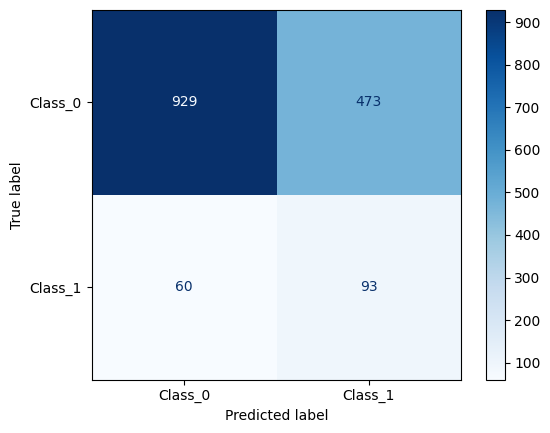

[[929 473]
 [ 60  93]]
              precision    recall  f1-score   support

           0       0.94      0.66      0.78      1402
           1       0.16      0.61      0.26       153

    accuracy                           0.66      1555
   macro avg       0.55      0.64      0.52      1555
weighted avg       0.86      0.66      0.73      1555

ROC-AUC : 0.6532
PR-AUC  : 0.1667


In [9]:
cm = confusion_matrix(y_test, results.prediction)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class_0", "Class_1"])
disp.plot(cmap=plt.cm.Blues)
plt.show()

print(cm)
print(classification_report(y_test, results.prediction))
print(f"ROC-AUC : {roc_auc_score(y_test, results.probability):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, results.probability):.4f}")

### Feature importance

In [11]:
fi = feature_importance(
    model,
    feature_names=bundle["feature_columns"],
    top_n=20,
)

print(fi.to_string(index=False))

                feature  importance
   objective_force_sell    0.074461
                 atr_14    0.058850
                   macd    0.039304
    objective_force_buy    0.038975
      rsi_neutral_x_atr    0.021394
         trend_strength    0.015862
    lag_return_autocorr    0.014786
           bb_atr_ratio    0.014262
             doji_score    0.013582
  ohlcv_lag_12_high_rel    0.012402
 ohlcv_lag_1_volume_rel    0.012088
 ohlcv_lag_8_volume_rel    0.011956
         lag_return_std    0.011786
                  month    0.010981
         volatility_20d    0.010954
          hl_range_mean    0.010583
 ohlcv_lag_5_volume_rel    0.010177
ohlcv_lag_14_volume_rel    0.010130
 ohlcv_lag_3_volume_rel    0.010037
           volume_trend    0.010027


### Objective-only rule

In [15]:
rate = y_train.groupby(X_train["objective_force_buy"]).mean()
score = X_test["objective_force_buy"].map(rate)
rule  = X_test["objective_force_buy"].astype(int)
print("train vuln. rate by objective:", rate.round(3).to_dict())
print("test  vuln. rate by objective:", y_test.groupby(X_test["objective_force_buy"]).mean().round(3).to_dict())
print(f"Objective rule  PR-AUC {average_precision_score(y_test, score):.3f}  ROC-AUC {roc_auc_score(y_test, score):.3f}")
print(f"Objective rule  P {precision_score(y_test, rule):.3f}  R {recall_score(y_test, rule):.3f}  F1 {f1_score(y_test, rule):.3f}")
print("vuln. rate by weekday train/test:", y_train.groupby(X_train.day_of_week).mean().round(3).to_dict(), y_test.groupby(X_test.day_of_week).mean().round(3).to_dict())
print("vuln. rate by quarter train/test:", y_train.groupby(X_train.quarter).mean().round(3).to_dict(), y_test.groupby(X_test.quarter).mean().round(3).to_dict())
print("train positives:", int(y_train.sum()), "/", len(y_train))

train vuln. rate by objective: {0: 0.075, 1: 0.153}
test  vuln. rate by objective: {0: 0.07, 1: 0.153}
Objective rule  PR-AUC 0.127  ROC-AUC 0.605
Objective rule  P 0.153  R 0.529  F1 0.237
vuln. rate by weekday train/test: {0: 0.116, 1: 0.104, 2: 0.114, 3: 0.109, 4: 0.102} {0: 0.09, 1: 0.097, 2: 0.106, 3: 0.113, 4: 0.085}
vuln. rate by quarter train/test: {1: 0.109, 2: 0.101, 3: 0.133, 4: 0.092} {1: 0.117, 2: 0.092, 3: 0.088, 4: 0.103}
train positives: 681 / 6256


### Augmented dataset model comparison

In [16]:
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, average_precision_score

X_all = load_X(X_test_PATH, logger)
y_all = load_y(y_test_PATH, logger)
ticker = np.where(X_all["attacked_ticker_GOOGL"] == 1, "GOOGL",
          np.where(X_all["attacked_ticker_AAPL"] == 1, "AAPL", "AMZN"))

models = {
    "GOOGL":      ("attack_day_googl.pkl", "metadata_googl.json"),
    "GOOGL+AAPL": ("attack_day.pkl",       "metadata.json"),
}
rows = []
for name, (m, meta) in models.items():
    b = load_attack_model(ATTACK_MODEL_FOLDER / m, ATTACK_MODEL_FOLDER / meta, logger)
    for subset in ["GOOGL", "AAPL", "all"]:
        mask = (ticker != "AMZN") if subset == "all" else (ticker == subset)
        X, y = X_all.loc[mask, b["feature_columns"]], y_all[mask]
        p = b["model"].predict_proba(X)[:, 1]
        pred = (p >= b["threshold"]).astype(int)
        rows.append(dict(model=name, test=subset, n=len(y), prev=y.mean(),
                         P=precision_score(y, pred), R=recall_score(y, pred), F1=f1_score(y, pred),
                         ROC=roc_auc_score(y, p), PR=average_precision_score(y, p)))
print(pd.DataFrame(rows).round(3).to_string(index=False))

2026-11-04 11:30:16 [INFO] Loaded X from '/content/drive/MyDrive/master-thesis/data/attack_dataset_(GOOGL)/attack_dataset_(GOOGL)_X_test.csv' – shape (3129, 133)
2026-11-04 11:30:22 [INFO] Applied feature engineering – new shape (3129, 157)
2026-11-04 11:30:22 [INFO] Loaded y from '/content/drive/MyDrive/master-thesis/data/attack_dataset_(GOOGL)/attack_dataset_(GOOGL)_y_test.csv' – 3129 samples
2026-11-04 11:30:22 [INFO]   Class 0 (non attack): 2858 (91.3%)
2026-11-04 11:30:22 [INFO]   Class 1 (attack): 271 (8.7%)
2026-11-04 11:30:22 [INFO]   Imbalance ratio: 1:11 (non attack : attack)
2026-11-04 11:30:22 [WARNING] Moderate imbalance detected (1:11). Recommend ImbalanceStrategy.SMOTE or CLASS_WEIGHT.
2026-11-04 11:30:22 [INFO] Model loaded from '/content/drive/MyDrive/master-thesis/notebooks/models/attack_day/attack_day_googl.pkl'.
2026-11-04 11:30:24 [INFO] Model loaded from '/content/drive/MyDrive/master-thesis/notebooks/models/attack_day/attack_day.pkl'.


     model  test    n  prev     P     R    F1   ROC    PR
     GOOGL GOOGL 1555 0.098 0.164 0.608 0.259 0.653 0.167
     GOOGL  AAPL 1574 0.075 0.121 0.508 0.196 0.606 0.133
     GOOGL   all 3129 0.087 0.144 0.565 0.230 0.634 0.149
GOOGL+AAPL GOOGL 1555 0.098 0.116 0.725 0.200 0.609 0.156
GOOGL+AAPL  AAPL 1574 0.075 0.083 0.712 0.148 0.598 0.121
GOOGL+AAPL   all 3129 0.087 0.099 0.720 0.174 0.603 0.138


### Precision–recall on the test set

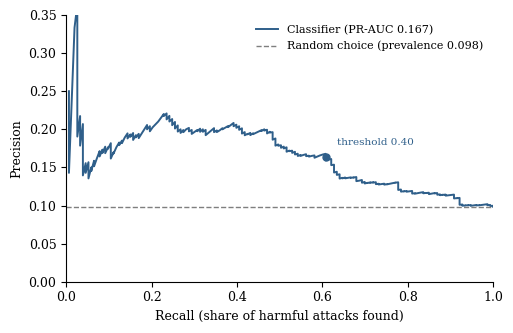

Saved: /content/drive/MyDrive/master-thesis/figures/precision_recall_reference.pdf
Prevalence 0.098 | classifier AP 0.167, operating point R=0.608 P=0.164


In [18]:
from sklearn.metrics import precision_recall_curve, average_precision_score, precision_score, recall_score

FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

y_true = np.asarray(y_test).astype(int)
prevalence = y_true.mean()

# classifier: probabilities and operating point at the validation threshold
p_clf = model.predict_proba(X_test[bundle["feature_columns"]])[:, 1]
prec_c, rec_c, _ = precision_recall_curve(y_true, p_clf)
ap_c = average_precision_score(y_true, p_clf)
op_c = (recall_score(y_true, p_clf >= threshold), precision_score(y_true, p_clf >= threshold))

plt.rcParams.update({"font.family": "serif", "font.size": 9})
fig, ax = plt.subplots(figsize=(5.2, 3.4))
# keep only the points with at least one harmful attack found (recall > 0):
# this also drops the point (recall 0, precision 1) that scikit-learn appends by convention
keep = rec_c > 0
rec_c, prec_c = rec_c[keep], prec_c[keep]
ax.plot(rec_c, prec_c, color="#2f5f8a", lw=1.4,
        label=f"Classifier (PR-AUC {ap_c:.3f})")
ax.plot(*op_c, "o", color="#2f5f8a", ms=5, zorder=3)
ax.annotate(f"threshold {threshold:.2f}", op_c, xytext=(8, 8), textcoords="offset points",
            fontsize=7.5, color="#2f5f8a")
ax.axhline(prevalence, color="#7f7f7f", ls="--", lw=1,
           label=f"Random choice (prevalence {prevalence:.3f})")

# the first few points (top-ranked attacks) are very noisy: keep the readable range
ymax = min(1.0, max(0.35, 1.15 * prec_c[rec_c >= 0.05].max()))
ax.set_xlim(0, 1.0)
ax.set_ylim(0, ymax)
ax.set_xlabel("Recall (share of harmful attacks found)")
ax.set_ylabel("Precision")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()

out = FIG_DIR / "precision_recall_reference.pdf"
fig.savefig(out, bbox_inches="tight")
fig.savefig(out.with_suffix(".png"), dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")
print(f"Prevalence {prevalence:.3f} | classifier AP {ap_c:.3f}, operating point R={op_c[0]:.3f} P={op_c[1]:.3f}")